# Tự Động Huấn Luyện & So Sánh Nhiều Cấu Hình (Chạy Được Cả Local & Kaggle)
Notebook này được tối ưu sẵn để **chạy trực tiếp trên Kaggle GPU (T4 / P100)** hoặc trên máy cá nhân:
1. **Tự động nhận diện môi trường:** Tự động tìm đường dẫn dataset multi-task.
2. **Tích hợp Dataset & Anti-Leakage:** Kiểm tra và loại bỏ rò rỉ dữ liệu giữa các tập Train/Val/Test.
3. **Đánh giá Baseline & FORGE MoE:** Tự động so sánh kết quả phục hồi ảnh giữa các mô hình.
4. **Lưu trữ & Visual Demo:** Tinh chỉnh mô hình tốt nhất, lưu checkpoint và render ảnh trực quan.

In [ ]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import math
import sys
import time
import random
import gc
import json
import shutil
import hashlib
import urllib.request
import glob
from collections import defaultdict
import torch.nn.functional as F
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms.functional as TF
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

# Tạo thư mục weights để lưu checkpoint
os.makedirs("weights", exist_ok=True)

candidate_paths = [
    '.', '..', 
    '/kaggle/working', 
    '/kaggle/working/Image-processing-project-integrating-MoE-and-Q-Former'
]

for p in candidate_paths:
    if os.path.exists(os.path.join(p, 'models')) and os.path.exists(os.path.join(p, 'utils')):
        abs_p = os.path.abspath(p)
        if abs_p not in sys.path:
            sys.path.insert(0, abs_p)
        break

# Import từ thư mục dự án
try:
    from models.forge import NAFNetBaseline, FORGEDeblurNet, ForgeMoEConv2d
    from utils.metrics import CharbonnierLoss, FFTLoss, DeblurCompositeLoss, calc_psnr, calc_ssim, count_parameters
    from utils.dataset import MultiTaskRestorationDataset, get_multitask_balanced_splits
    from models.prompt_forge import PromptFORGEDeblurNet
except ImportError as e:
    print(f"Cảnh báo Import: {e}. Vui lòng kiểm tra lại cấu trúc thư mục models/ và utils/.")

# ------------------------------------------------------------------------------
# Định nghĩa WarmupCosineScheduler
# ------------------------------------------------------------------------------
class WarmupCosineScheduler(optim.lr_scheduler._LRScheduler):
    def __init__(self, optimizer, warmup_epochs, total_epochs, min_lr=1e-7, last_epoch=-1):
        self.warmup_epochs = warmup_epochs
        self.total_epochs = total_epochs
        self.min_lr = min_lr
        super().__init__(optimizer, last_epoch)

    def get_lr(self):
        if self.last_epoch < self.warmup_epochs:
            alpha = float(self.last_epoch + 1) / float(max(1, self.warmup_epochs))
            return [base_lr * alpha for base_lr in self.base_lrs]
        else:
            progress = float(self.last_epoch - self.warmup_epochs) / float(max(1, self.total_epochs - self.warmup_epochs))
            progress = min(1.0, max(0.0, progress))
            cosine_decay = 0.5 * (1.0 + math.cos(math.pi * progress))
            return [self.min_lr + (base_lr - self.min_lr) * cosine_decay for base_lr in self.base_lrs]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Thiết bị đang sử dụng: {device}")

pretrained_url = "https://huggingface.co/Jacid23/third-eye-models/resolve/5c2e322323888d8d26852f06715ccc6eb61ea795/NAFNet-GoPro-width64.pth"
nafnet_ckpt_path = os.path.join("weights", "NAFNet-GoPro-width64.pth")

if not os.path.exists(nafnet_ckpt_path):
    print("--> Đang tải pretrained NAFNet từ Hugging Face...")
    urllib.request.urlretrieve(pretrained_url, nafnet_ckpt_path)
    print("--> Tải xuống checkpoint thành công!")
else:
    print(f"--> Đã tìm thấy checkpoint tại: {nafnet_ckpt_path}")

nafnet_state_dict = torch.load(nafnet_ckpt_path, map_location=device)
if 'params' in nafnet_state_dict:
    nafnet_state_dict = nafnet_state_dict['params']
elif 'model_state_dict' in nafnet_state_dict:
    nafnet_state_dict = nafnet_state_dict['model_state_dict']
print("--> Đã nạp thành công nafnet_state_dict vào bộ nhớ!")

Thiết bị đang sử dụng: cuda
--> Đã tìm thấy checkpoint tại: weights\NAFNet-GoPro-width64.pth
--> Đã nạp thành công nafnet_state_dict vào bộ nhớ!


### Khởi tạo Dữ liệu Multi-Task

In [2]:
def auto_detect_multitask_dataset():
    candidate_names = ['dataset_multitask_unified', 'multitask_dataset']
    prefixes = ['.', '..', '/kaggle/input/*', '/kaggle/input']
    
    for prefix in prefixes:
        for path in glob.glob(prefix):
            for c_name in candidate_names:
                full_p = os.path.join(path, c_name)
                if os.path.exists(full_p):
                    return os.path.abspath(full_p)
    return 'dataset_multitask_unified'

multitask_dir = auto_detect_multitask_dataset()
print(f"--> Đã tìm thấy đường dẫn Multitask Dataset: {multitask_dir}")

# Giới hạn số lượng ảnh
MAX_TRAIN_SAMPLES = 1200  # Giới hạn train/task
MAX_TEST_SAMPLES = 200    # Giới hạn test/task

# Tự động chia dataset cân bằng theo từng task
train_samples, val_samples, test_samples = get_multitask_balanced_splits(
    root_dir=multitask_dir,
    val_ratio=0.15,
    seed=42,
    max_train_samples_per_task=MAX_TRAIN_SAMPLES,
    max_test_samples_per_task=MAX_TEST_SAMPLES
)

# Khởi tạo các tập Dataset
train_sub_ds = MultiTaskRestorationDataset(samples=train_samples, crop_size=192, is_train=True)
val_sub_ds = MultiTaskRestorationDataset(samples=val_samples, crop_size=256, is_train=False)
test_sub_ds = MultiTaskRestorationDataset(samples=test_samples, crop_size=256, is_train=False)

# DataLoader
num_workers_cfg = 0 if os.name == 'nt' else 2
val_loader = DataLoader(val_sub_ds, batch_size=1, shuffle=False, num_workers=num_workers_cfg, pin_memory=True)
test_loader = DataLoader(test_sub_ds, batch_size=1, shuffle=False, num_workers=num_workers_cfg, pin_memory=True)

print(f"--> Khởi tạo thành công DataLoader: Train={len(train_sub_ds)} | Val={len(val_sub_ds)} | Test={len(test_sub_ds)}")

--> Đã tìm thấy đường dẫn Multitask Dataset: e:\DuAn\Image-processing-project-integrating-MoE-and-Q-Former\dataset_multitask_unified
--> [Optimized Leakproof Split] Chia dữ liệu cho TẤT CẢ các task: e:\DuAn\Image-processing-project-integrating-MoE-and-Q-Former\dataset_multitask_unified
     + TRAIN / VAL : Nguồn từ folder <task>/train/ (Max 1200 ảnh/task)
     + TEST        : Nguồn từ folder <task>/test/  (Max 200 ảnh/task)
  + Task [deblur  ] (ID: 0): Train = 1010 | Val = 180 | Test = 200
  + Task [dehaze  ] (ID: 1): Train =  975 | Val = 210 | Test = 200
  + Task [denoise ] (ID: 2): Train =   83 | Val =  34 | Test =  42
  + Task [derain  ] (ID: 3): Train = 1013 | Val = 185 | Test = 200
  + Task [desnow  ] (ID: 4): Train = 1020 | Val = 180 | Test = 200
  + Task [lowlight] (ID: 5): Train =  586 | Val = 103 | Test = 100
--------------------------------------------------------------------------------
--> TỔNG CỘNG LEAKPROOF: Train = 4687 | Val = 892 | Test = 942 ảnh
--> Đã ghi file Cache 

### 🔍 Audit Kiểm Tra Data Leakage (Trùng Lặp Target MD5)

In [3]:
def get_file_md5(filepath):
    hasher = hashlib.md5()
    with open(filepath, 'rb') as f:
        while chunk := f.read(8192):
            hasher.update(chunk)
    return hasher.hexdigest()

def audit_split_data_leakage(train_samples, val_samples, test_samples):
    print("=" * 80)
    print("🔍 BÁO CÁO AUDIT CHỐNG DATA LEAKAGE CÁC TẬP TRAIN / VAL / TEST (MD5 Target Hash)")
    print("=" * 80)

    all_tasks = sorted(list(set([s[3] for s in train_samples + val_samples + test_samples])))
    total_leaks = 0

    for task_name in all_tasks:
        tr_task = [s for s in train_samples if s[3] == task_name]
        val_task = [s for s in val_samples if s[3] == task_name]
        te_task = [s for s in test_samples if s[3] == task_name]

        # Tính MD5 Target (Clean Ground Truth) cho từng tập
        tr_md5_map = {get_file_md5(s[1]): s[1] for s in tr_task}
        val_md5_map = {get_file_md5(s[1]): s[1] for s in val_task}
        te_md5_map = {get_file_md5(s[1]): s[1] for s in te_task}

        # Đếm trùng chéo
        tr_val_overlap = set(tr_md5_map.keys()).intersection(set(val_md5_map.keys()))
        tr_te_overlap = set(tr_md5_map.keys()).intersection(set(te_md5_map.keys()))
        val_te_overlap = set(val_md5_map.keys()).intersection(set(te_md5_map.keys()))

        task_leaks = len(tr_val_overlap) + len(tr_te_overlap) + len(val_te_overlap)
        total_leaks += task_leaks

        print(f"\n📌 TASK [{task_name.upper()}]:")
        print(f"  • Mẫu Dữ Liệu : Train = {len(tr_task):4d} | Val = {len(val_task):3d} | Test = {len(te_task):3d}")
        print(f"  • Target Clean: Train = {len(tr_md5_map):4d} | Val = {len(val_md5_map):3d} | Test = {len(te_md5_map):3d} (MD5 độc lập)")
        
        if tr_val_overlap:
            print(f"  🚨 LEAK TRAIN - VAL : Phát hiện {len(tr_val_overlap)} ảnh Clean trùng nội dung!")
        else:
            print("  ✅ Train vs Val     : 0% Leakage (Hoàn toàn độc lập)")

        if tr_te_overlap:
            print(f"  🚨 LEAK TRAIN - TEST: Phát hiện {len(tr_te_overlap)} ảnh Clean trùng nội dung!")
        else:
            print("  ✅ Train vs Test    : 0% Leakage (Hoàn toàn độc lập)")

        if val_te_overlap:
            print(f"  🚨 LEAK VAL - TEST  : Phát hiện {len(val_te_overlap)} ảnh Clean trùng nội dung!")
        else:
            print("  ✅ Val vs Test      : 0% Leakage (Hoàn toàn độc lập)")

    print("-" * 80)
    if total_leaks == 0:
        print("🎉 TẤT CẢ CÁC TÁC VỤ ĐỀU ĐẠT CHUẨN LEAKPROOF 100%! Chỉ số Validation/Test sẽ hoàn toàn chính xác.")
    else:
        print(f"⚠️ PHÁT HIỆN TỔNG CỘNG {total_leaks} ĐIỂM LEAKAGE. Vui lòng kiểm tra lại utils/dataset.py!")
    print("=" * 80)

audit_split_data_leakage(train_samples, val_samples, test_samples)

🔍 BÁO CÁO AUDIT CHỐNG DATA LEAKAGE CÁC TẬP TRAIN / VAL / TEST (MD5 Target Hash)

📌 TASK [DEBLUR]:
  • Mẫu Dữ Liệu : Train = 1010 | Val = 180 | Test = 200
  • Target Clean: Train = 1010 | Val = 180 | Test = 200 (MD5 độc lập)
  ✅ Train vs Val     : 0% Leakage (Hoàn toàn độc lập)
  ✅ Train vs Test    : 0% Leakage (Hoàn toàn độc lập)
  ✅ Val vs Test      : 0% Leakage (Hoàn toàn độc lập)

📌 TASK [DEHAZE]:
  • Mẫu Dữ Liệu : Train =  975 | Val = 210 | Test = 200
  • Target Clean: Train =   28 | Val =   6 | Test =   6 (MD5 độc lập)
  ✅ Train vs Val     : 0% Leakage (Hoàn toàn độc lập)
  ✅ Train vs Test    : 0% Leakage (Hoàn toàn độc lập)
  ✅ Val vs Test      : 0% Leakage (Hoàn toàn độc lập)

📌 TASK [DENOISE]:
  • Mẫu Dữ Liệu : Train =   83 | Val =  34 | Test =  42
  • Target Clean: Train =   83 | Val =  34 | Test =  42 (MD5 độc lập)
  ✅ Train vs Val     : 0% Leakage (Hoàn toàn độc lập)
  ✅ Train vs Test    : 0% Leakage (Hoàn toàn độc lập)
  ✅ Val vs Test      : 0% Leakage (Hoàn toàn độc lập)



### Định Nghĩa Hàm Đánh Giá Multi-Task

In [4]:
def evaluate_multitask_model(model, loader, desc="Validating", max_size=1024):
    model.eval()
    task_psnr = defaultdict(list)
    task_ssim = defaultdict(list)
    
    multiple = 16 
    pbar_eval = tqdm(loader, desc=f"[{desc}]", leave=False)
    
    with torch.no_grad():
        for inputs, targets, task_ids, task_names in pbar_eval:
            inputs, targets = inputs.to(device), targets.to(device)

            # Center Crop nếu ảnh quá lớn để tránh OOM
            _, _, h_orig, w_orig = inputs.shape
            if h_orig > max_size or w_orig > max_size:
                h_crop = min(h_orig, max_size)
                w_crop = min(w_orig, max_size)
                top = (h_orig - h_crop) // 2
                left = (w_orig - w_crop) // 2
                inputs = inputs[:, :, top:top+h_crop, left:left+w_crop]
                targets = targets[:, :, top:top+h_crop, left:left+w_crop]

            # Padding để H và W chia hết cho 16
            h, w = inputs.shape[2], inputs.shape[3]
            H = ((h + multiple - 1) // multiple) * multiple
            W = ((w + multiple - 1) // multiple) * multiple
            pad_h, pad_w = H - h, W - w
            inputs_padded = F.pad(inputs, (0, pad_w, 0, pad_h), mode='reflect')

            # Đánh giá bằng FP32
            out = model(inputs_padded.float())

            preds = out[0] if isinstance(out, tuple) else out
            preds = preds[:, :, :h, :w]
            preds = torch.clamp(preds, 0.0, 1.0)
            
            # Tính toán metric
            p_val = calc_psnr(preds, targets)
            s_val = calc_ssim(preds, targets)
            
            p_item = p_val.item() if torch.is_tensor(p_val) else p_val
            s_item = s_val.item() if torch.is_tensor(s_val) else s_val

            for t_name in task_names:
                if not math.isnan(p_item):
                    task_psnr[t_name].append(p_item)
                if not math.isnan(s_item):
                    task_ssim[t_name].append(s_item)

    all_psnr = [val for sublist in task_psnr.values() for val in sublist if not math.isnan(val)]
    all_ssim = [val for sublist in task_ssim.values() for val in sublist if not math.isnan(val)]
    
    avg_psnr = sum(all_psnr) / len(all_psnr) if all_psnr else 0.0
    avg_ssim = sum(all_ssim) / len(all_ssim) if all_ssim else 0.0

    task_summary = {}
    for t_name in task_psnr:
        p_list = [v for v in task_psnr[t_name] if not math.isnan(v)]
        s_list = [v for v in task_ssim[t_name] if not math.isnan(v)]
        t_p = sum(p_list) / len(p_list) if p_list else 0.0
        t_s = sum(s_list) / len(s_list) if s_list else 0.0
        task_summary[t_name] = {'psnr': t_p, 'ssim': t_s}

    return avg_psnr, avg_ssim, task_summary

### Đánh giá baseline NAFNet gốc

In [5]:
baseline_model = NAFNetBaseline(
    img_channel=3, 
    width=64, 
    enc_blk_nums=[1, 1, 1, 28], 
    middle_blk_num=1, 
    dec_blk_nums=[1, 1, 1, 1]
).to(device)

baseline_model.load_state_dict(nafnet_state_dict, strict=True)

print("\n===================================================")
print(" ĐANG ĐÁNH GIÁ PURE NAFNet BASELINE TRÊN TẬP TEST MULTITASK...")
print("===================================================")
baseline_psnr, baseline_ssim, baseline_summary = evaluate_multitask_model(baseline_model, test_loader, desc="Baseline Test")

print(f"\n KẾT QUẢ PURE NAFNET BASELINE (TRUNG BÌNH CÁC TASK):")
print(f"   + PSNR Trung bình : {baseline_psnr:.2f} dB")
print(f"   + SSIM Trung bình : {baseline_ssim:.4f}")
print("\n CHI TIẾT THEO TỪNG TASK:")
for t_name, metrics in sorted(baseline_summary.items()):
    print(f"   - Task [{t_name:8s}]: PSNR = {metrics['psnr']:.2f} dB | SSIM = {metrics['ssim']:.4f}")

del baseline_model
gc.collect()
torch.cuda.empty_cache()


 ĐANG ĐÁNH GIÁ PURE NAFNet BASELINE TRÊN TẬP TEST MULTITASK...


[Baseline Test]:   0%|          | 0/942 [00:00<?, ?it/s]


 KẾT QUẢ PURE NAFNET BASELINE (TRUNG BÌNH CÁC TASK):
   + PSNR Trung bình : 20.48 dB
   + SSIM Trung bình : 0.6662

 CHI TIẾT THEO TỪNG TASK:
   - Task [deblur  ]: PSNR = 32.23 dB | SSIM = 0.9350
   - Task [dehaze  ]: PSNR = 15.81 dB | SSIM = 0.7470
   - Task [denoise ]: PSNR = 14.67 dB | SSIM = 0.2781
   - Task [derain  ]: PSNR = 20.70 dB | SSIM = 0.6346
   - Task [desnow  ]: PSNR = 19.93 dB | SSIM = 0.6731
   - Task [lowlight]: PSNR = 9.45 dB | SSIM = 0.1794


### Cấu Hình & Huấn Luyện Tinh Chỉnh Mô Hình FORGE MoE

In [ ]:
BEST_CONFIG = {
    'name': 'FORGE_MoE_MainTrain',
    'lr': 1e-4,
    'batch_size': 2,
    'freeze_backbone': True,
}

COMMON_CONFIG = {
    'width': 64,
    'enc_blk_nums': [1, 1, 1, 28],
    'middle_blk_num': 1,
    'dec_blk_nums': [1, 1, 1, 1],
    'num_queries': 16,
    'num_experts': 8,
    'top_k': 2,
    'r': 32,
    'rb': 64,
    'aux_weight': 1e-4,
    'moe_in_decoder': True,
}

MAX_FINE_TUNE_EPOCHS = 5  
PATIENCE = 5               
MIN_DELTA = 0.02           

print(f"\n===================================================")
print(f" BẮT ĐẦU HUẤN LUYỆN KỸ MÔ HÌNH FORGE MoE")
print(f"===================================================")

num_workers_ft = 0 if os.name == 'nt' else 2
train_loader_full = DataLoader(
    train_sub_ds, 
    batch_size=BEST_CONFIG['batch_size'], 
    shuffle=True, 
    num_workers=num_workers_ft, 
    pin_memory=True
)

final_model = PromptFORGEDeblurNet(
    img_channel=3, 
    out_channels=3,
    width=COMMON_CONFIG['width'],
    enc_blk_nums=COMMON_CONFIG['enc_blk_nums'],
    middle_blk_num=COMMON_CONFIG['middle_blk_num'],
    dec_blk_nums=COMMON_CONFIG['dec_blk_nums'],
    num_prompts=10,                     # Thêm tham số PGM Bank Size
    num_experts=COMMON_CONFIG['num_experts'],
    top_k=COMMON_CONFIG['top_k'],
    r=COMMON_CONFIG['r'],
    rb=COMMON_CONFIG['rb'],
    moe_in_decoder=COMMON_CONFIG['moe_in_decoder'],
).to(device)

# Load pretrained NAFNet weights
final_model.load_state_dict(nafnet_state_dict, strict=False)

# Cấy ghép SVD Anchor MoE
for m in final_model.modules():
    if isinstance(m, ForgeMoEConv2d):
        m.init_svd(m.W0.weight)

if BEST_CONFIG['freeze_backbone']:
    final_model.freeze_backbone(True)

trainable_params = [p for p in final_model.parameters() if p.requires_grad]
n_trainable = sum(p.numel() for p in trainable_params)
n_total = sum(p.numel() for p in final_model.parameters())
print(f"--> Số tham số huấn luyện: {n_trainable:,} / {n_total:,} ({100*n_trainable/n_total:.1f}%)")

optimizer = optim.AdamW(trainable_params, lr=BEST_CONFIG['lr'], weight_decay=1e-4)
scheduler = WarmupCosineScheduler(optimizer, warmup_epochs=1, total_epochs=MAX_FINE_TUNE_EPOCHS, min_lr=1e-7)
criterion = DeblurCompositeLoss(eps=1e-3, fft_weight=0.05, vgg_weight=0.0)

best_val_psnr = 0.0
no_improve_epochs = 0
best_checkpoint_path = os.path.join("weights", f"best_model_{BEST_CONFIG['name']}.pth")

for epoch in range(1, MAX_FINE_TUNE_EPOCHS + 1):
    final_model.train()
    running_loss = 0.0
    valid_batches = 0
    
    pbar = tqdm(train_loader_full, desc=f"[Main Train] Epoch {epoch:02d}/{MAX_FINE_TUNE_EPOCHS:02d}")
    
    for inputs, targets, task_ids, task_names in pbar:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad(set_to_none=True)
        
        preds, aux_loss = final_model(inputs.float())
        recon_loss = criterion(preds, targets.float())
        
        if torch.isnan(aux_loss) or torch.isinf(aux_loss):
            aux_loss = torch.tensor(0.0, device=device)
            
        total_loss = recon_loss + COMMON_CONFIG['aux_weight'] * aux_loss
        
        if torch.isnan(total_loss) or torch.isinf(total_loss):
            print(f"\n Cảnh báo: Phát hiện NaN loss ở batch, bỏ qua update batch này.")
            continue
            
        total_loss.backward()
        torch.nn.utils.clip_grad_norm_(trainable_params, max_norm=1.0)
        optimizer.step()
            
        running_loss += total_loss.item()
        valid_batches += 1
        pbar.set_postfix({'loss': f"{total_loss.item():.4f}", 'lr': f"{optimizer.param_groups[0]['lr']:.2e}"})
        
        del inputs, targets, preds
        
    epoch_loss = running_loss / max(1, valid_batches)
    scheduler.step()
    
    # Validation Check
    val_psnr, val_ssim, val_summary = evaluate_multitask_model(final_model, val_loader, desc="Validation Check")
    print(f"--> [Epoch {epoch:02d}] Train Loss: {epoch_loss:.4f} | Val PSNR: {val_psnr:.2f} dB | SSIM: {val_ssim:.4f}")
    
    if val_psnr - best_val_psnr > MIN_DELTA:
        best_val_psnr = val_psnr
        no_improve_epochs = 0
        torch.save(final_model.state_dict(), best_checkpoint_path)
        print(f"    [+] Cải thiện PSNR. Đã lưu checkpoint: {best_checkpoint_path}")
    else:
        no_improve_epochs += 1
        print(f"    [-] Không cải thiện ({no_improve_epochs}/{PATIENCE} epoch).")
        
    if no_improve_epochs >= PATIENCE:
        print(f"\n KÍCH HOẠT EARLY STOPPING.")
        break

gc.collect()
torch.cuda.empty_cache()


 BẮT ĐẦU HUẤN LUYỆN KỸ MÔ HÌNH FORGE MoE
--> Số tham số huấn luyện: 579,993 / 68,433,241 (0.8%)


[Main Train] Epoch 01/05:   0%|          | 0/2344 [00:00<?, ?it/s]

[Validation Check]:   0%|          | 0/892 [00:00<?, ?it/s]

--> [Epoch 01] Train Loss: 25.5254 | Val PSNR: 22.48 dB | SSIM: 0.7058
    [+] Cải thiện PSNR. Đã lưu checkpoint: weights\best_model_FORGE_MoE_MainTrain.pth


[Main Train] Epoch 02/05:   0%|          | 0/2344 [00:00<?, ?it/s]

...

[Validation Check]:   0%|          | 0/892 [00:00<?, ?it/s]

--> [Epoch 04] Train Loss: 12.3631 | Val PSNR: 23.46 dB | SSIM: 0.7142
    [+] Cải thiện PSNR. Đã lưu checkpoint: weights\best_model_FORGE_MoE_MainTrain.pth


[Main Train] Epoch 05/05:   0%|          | 0/2344 [00:00<?, ?it/s]

[Validation Check]:   0%|          | 0/892 [00:00<?, ?it/s]

--> [Epoch 05] Train Loss: 7.3291 | Val PSNR: 23.45 dB | SSIM: 0.7093
    [-] Không cải thiện (1/5 epoch).


### Trực Quan Hóa Kết Quả (Visual Demo)

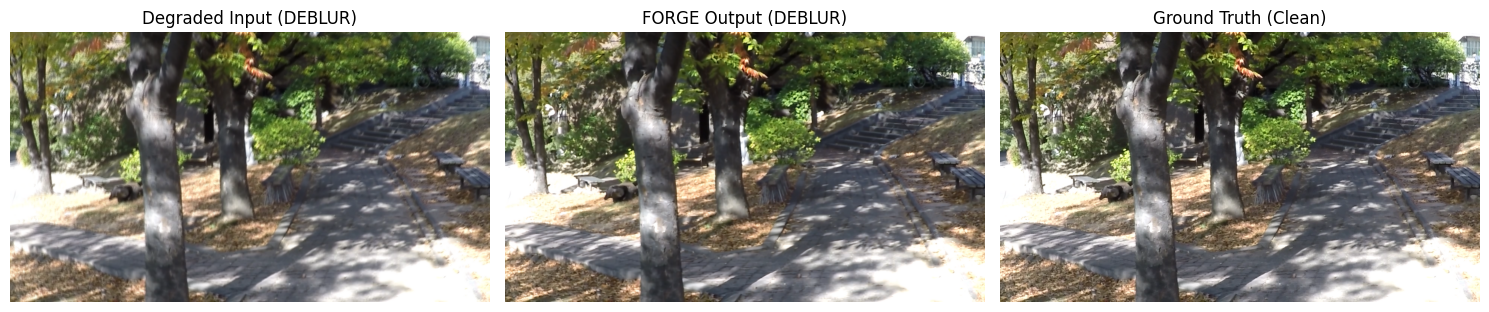

In [7]:
def visualize_results(model, loader, num_imgs=3):
    model.eval()
    inputs, targets, task_ids, task_names = next(iter(loader))
    inputs, targets = inputs.to(device), targets.to(device)
    
    with torch.no_grad():
        out = model(inputs)
        preds = out[0] if isinstance(out, tuple) else out
        preds = torch.clamp(preds, 0.0, 1.0)
    
    inputs = inputs.cpu()
    targets = targets.cpu()
    preds = preds.cpu()
    
    batch_size = min(num_imgs, inputs.size(0))
    fig, axes = plt.subplots(batch_size, 3, figsize=(15, 5 * batch_size))
    
    if batch_size == 1:
        axes = [axes]
        
    for i in range(batch_size):
        t_name = task_names[i] if isinstance(task_names, (list, tuple)) else task_names
        axes[i][0].imshow(inputs[i].permute(1, 2, 0))
        axes[i][0].set_title(f"Degraded Input ({t_name.upper()})")
        axes[i][0].axis('off')
        
        axes[i][1].imshow(preds[i].permute(1, 2, 0))
        axes[i][1].set_title(f"FORGE Output ({t_name.upper()})")
        axes[i][1].axis('off')
        
        axes[i][2].imshow(targets[i].permute(1, 2, 0))
        axes[i][2].set_title("Ground Truth (Clean)")
        axes[i][2].axis('off')
        
    plt.tight_layout()
    plt.show()

if 'final_model' in locals():
    visualize_results(final_model, test_loader, num_imgs=3)

### Đánh Giá Mô Hình Best FORGE Trên Tập Test

In [ ]:
best_model = PromptFORGEDeblurNet(
    img_channel=3,
    out_channels=3,
    width=COMMON_CONFIG['width'],
    enc_blk_nums=COMMON_CONFIG['enc_blk_nums'],
    middle_blk_num=COMMON_CONFIG['middle_blk_num'],
    dec_blk_nums=COMMON_CONFIG['dec_blk_nums'],
    num_queries=COMMON_CONFIG.get('num_queries', 16),
    num_experts=COMMON_CONFIG.get('num_experts', 4),
    top_k=COMMON_CONFIG.get('top_k', 2),
    r=COMMON_CONFIG['r'],
    rb=COMMON_CONFIG['rb'],
    moe_in_decoder=COMMON_CONFIG.get('moe_in_decoder', False),
    decoder_r=COMMON_CONFIG.get('decoder_r', None),
    decoder_rb=COMMON_CONFIG.get('decoder_rb', None),
    prompt_dim=COMMON_CONFIG.get('prompt_dim', 64),
    num_prompts=COMMON_CONFIG.get('num_prompts', 5),
).to(device)

best_checkpoint_path = os.path.join("weights", f"best_model_{BEST_CONFIG['name']}.pth")

if os.path.exists(best_checkpoint_path):
    best_state_dict = torch.load(best_checkpoint_path, map_location=device)
    best_model.load_state_dict(best_state_dict, strict=True)
    print(f"--> Đã nạp checkpoint thành công từ: {best_checkpoint_path}")
else:
    print(f"--> Cảnh báo: Không tìm thấy checkpoint {best_checkpoint_path}, đánh giá bằng trọng số hiện tại của mô hình.")

print("\n===================================================")
print(f" ĐANG ĐÁNH GIÁ MÔ HÌNH BEST FORGE ({BEST_CONFIG['name']}) TRÊN TẬP TEST...")
print("===================================================")

forge_psnr, forge_ssim, forge_summary = evaluate_multitask_model(best_model, test_loader, desc="FORGE Best Test")

print(f"\n KẾT QUẢ TỔNG QUAN MÔ HÌNH FORGE ({BEST_CONFIG['name']}):")
print(f"   + PSNR Trung bình : {forge_psnr:.2f} dB")
print(f"   + SSIM Trung bình : {forge_ssim:.4f}")

if 'baseline_psnr' in locals():
    print(f"   + Cải thiện so với Baseline : {forge_psnr - baseline_psnr:+.2f} dB PSNR | {forge_ssim - baseline_ssim:+.4f} SSIM")

print("\n BẢNG KẾT QUẢ CHI TIẾT CÁC TÁC VỤ:")
for t_name, metrics in sorted(forge_summary.items()):
    base_p = baseline_summary[t_name]['psnr'] if 'baseline_summary' in locals() and t_name in baseline_summary else None
    diff_str = f" (Δ vs Base: {metrics['psnr'] - base_p:+.2f} dB)" if base_p is not None else ""
    print(f"   - Task [{t_name:8s}]: PSNR = {metrics['psnr']:.2f} dB | SSIM = {metrics['ssim']:.4f}{diff_str}")

del best_model
gc.collect()
torch.cuda.empty_cache()

--> Đã nạp checkpoint thành công từ: weights\best_model_FORGE_MoE_MainTrain.pth

 ĐANG ĐÁNH GIÁ MÔ HÌNH BEST FORGE (FORGE_MoE_MainTrain) TRÊN TẬP TEST...


[FORGE Best Test]:   0%|          | 0/942 [00:00<?, ?it/s]


 KẾT QUẢ TỔNG QUAN MÔ HÌNH FORGE (FORGE_MoE_MainTrain):
   + PSNR Trung bình : 22.53 dB
   + SSIM Trung bình : 0.7160
   + Cải thiện so với Baseline : +2.05 dB PSNR | +0.0499 SSIM

 BẢNG KẾT QUẢ CHI TIẾT CÁC TÁC VỤ:
   - Task [deblur  ]: PSNR = 31.12 dB | SSIM = 0.9224 (Δ vs Base: -1.12 dB)
   - Task [dehaze  ]: PSNR = 19.76 dB | SSIM = 0.7861 (Δ vs Base: +3.95 dB)
   - Task [denoise ]: PSNR = 12.81 dB | SSIM = 0.2412 (Δ vs Base: -1.87 dB)
   - Task [derain  ]: PSNR = 23.44 dB | SSIM = 0.7069 (Δ vs Base: +2.74 dB)
   - Task [desnow  ]: PSNR = 21.49 dB | SSIM = 0.6965 (Δ vs Base: +1.56 dB)
   - Task [lowlight]: PSNR = 15.26 dB | SSIM = 0.4198 (Δ vs Base: +5.81 dB)
